# ĐỒ ÁN 1: PHÂN TÍCH NHÂN KHẨU HỌC VÀ DỰ ĐOÁN THU NHẬP CÁ NHÂN (US ADULT CENSUS)
## Phần 1: Khám phá, Tiền xử lý dữ liệu và Trực quan hóa (EDA)
**Nhóm thực hiện: 1_2 - Lớp: DHKL18A1HN**
- Đào Đoàn Huy Phúc (Trưởng nhóm - MSV: 24174600034)
- Mai Đức Nhân (MSV: 24174600026)
- Cao Nguyên Ngọc (MSV: 24174600052)
- Nguyễn Văn Dũng (MSV: 22174600097)
- Trịnh Phương Thùy

**Giảng viên hướng dẫn:** ThS. Trần Chí Lê

### 1. Import các thư viện cần thiết

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Cấu hình font và style trực quan
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
%matplotlib inline

### 2. Thu thập và kiểm tra cấu trúc dữ liệu thô (Task 1 - Thùy)
- Nguồn dữ liệu: Adult Census Income Dataset (Kaggle)
- Mục tiêu: Kiểm tra số dòng, số cột, kiểu dữ liệu, các giá trị thiếu '?' và bản ghi trùng lặp.

In [2]:
raw_data_path = '../data/adult_raw.csv'
df_raw = pd.read_csv(raw_data_path)
print(f'Kích thước dữ liệu ban đầu: {df_raw.shape[0]} dòng, {df_raw.shape[1]} cột')
df_raw.head(5)

Kích thước dữ liệu ban đầu: 32561 dòng, 15 cột


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
df_raw.info()
print('\nSố bản ghi trùng lặp:', df_raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Số bản ghi trùng lặp: 24


### 3. Làm sạch và tiền xử lý dữ liệu (Task 2 - Nhân)
- Chuẩn hóa tên cột thành snake_case.
- Loại bỏ bản ghi trùng lặp.
- Xử lý các giá trị thiếu '?' bằng phương pháp Mode Imputation theo đề cương.
- Tạo biến mục tiêu nhị phân `income_num` (0: <=50K, 1: >50K).

In [4]:
# 1. Chuẩn hóa tên cột
df = df_raw.copy()
df.columns = [c.strip().replace('.', '_').lower() for c in df.columns]

# 2. Xóa các bản ghi trùng lặp
n_dups = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f'Đã loại bỏ {n_dups} dòng trùng lặp. Còn lại {len(df)} dòng.')

# 3. Thay thế '?' bằng NaN
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip().replace('?', np.nan)

# 4. Điền giá trị thiếu bằng Mode
missing_cols = ['workclass', 'occupation', 'native_country']
for col in missing_cols:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f'Cột {col}: điền mode "{mode_val}"')

# 5. Mã hóa biến mục tiêu
df['income_num'] = (df['income'] == '>50K').astype(int)

# 6. Xuất dữ liệu sạch
df.to_csv('../data/adult_cleaned.csv', index=False)
print('Kích thước sau làm sạch:', df.shape)

Đã loại bỏ 24 dòng trùng lặp. Còn lại 32537 dòng.


Cột workclass: điền mode "Private"
Cột occupation: điền mode "Prof-specialty"
Cột native_country: điền mode "United-States"


Kích thước sau làm sạch: (32537, 16)


### 4. Trực quan số lượng & Tỷ lệ đơn (Task 3 - Ngọc)
- Vẽ biểu đồ cột và biểu đồ tròn thể hiện tỷ lệ giữa hai nhóm thu nhập (<=50K vs >50K).
- Khảo sát phân bố theo các biến nhân khẩu học chính.

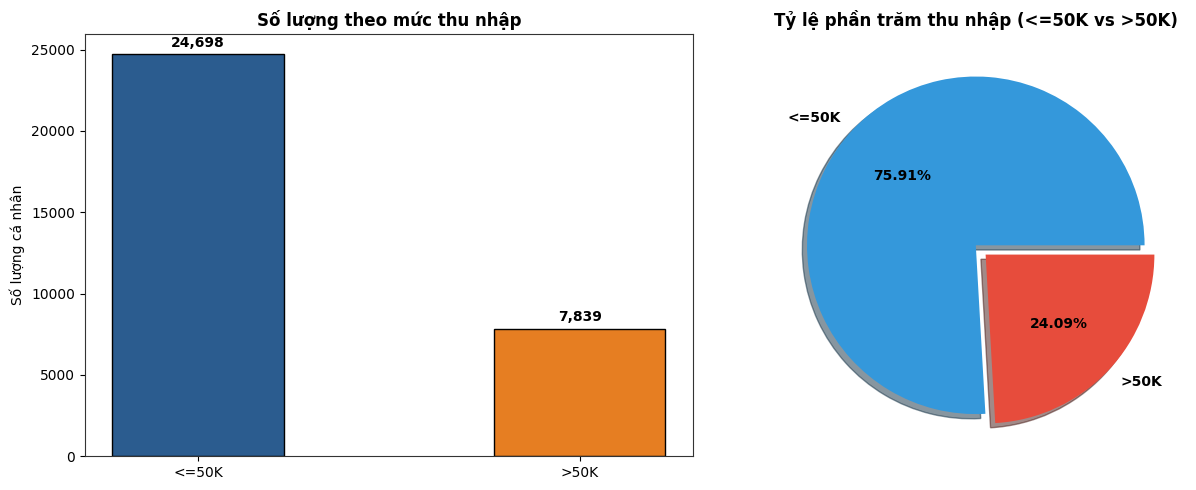

In [5]:
counts = df['income'].value_counts()
pcts = df['income'].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
bars = axes[0].bar(counts.index, counts.values, color=['#2b5c8f', '#e67e22'], width=0.45, edgecolor='black')
axes[0].set_title('Số lượng theo mức thu nhập', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Số lượng cá nhân')
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 300, f'{int(h):,}', ha='center', va='bottom', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=counts.index, autopct='%1.2f%%', colors=['#3498db', '#e74c3c'], explode=(0, 0.08), shadow=True, textprops={'fontweight': 'bold'})
axes[1].set_title('Tỷ lệ phần trăm thu nhập (<=50K vs >50K)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

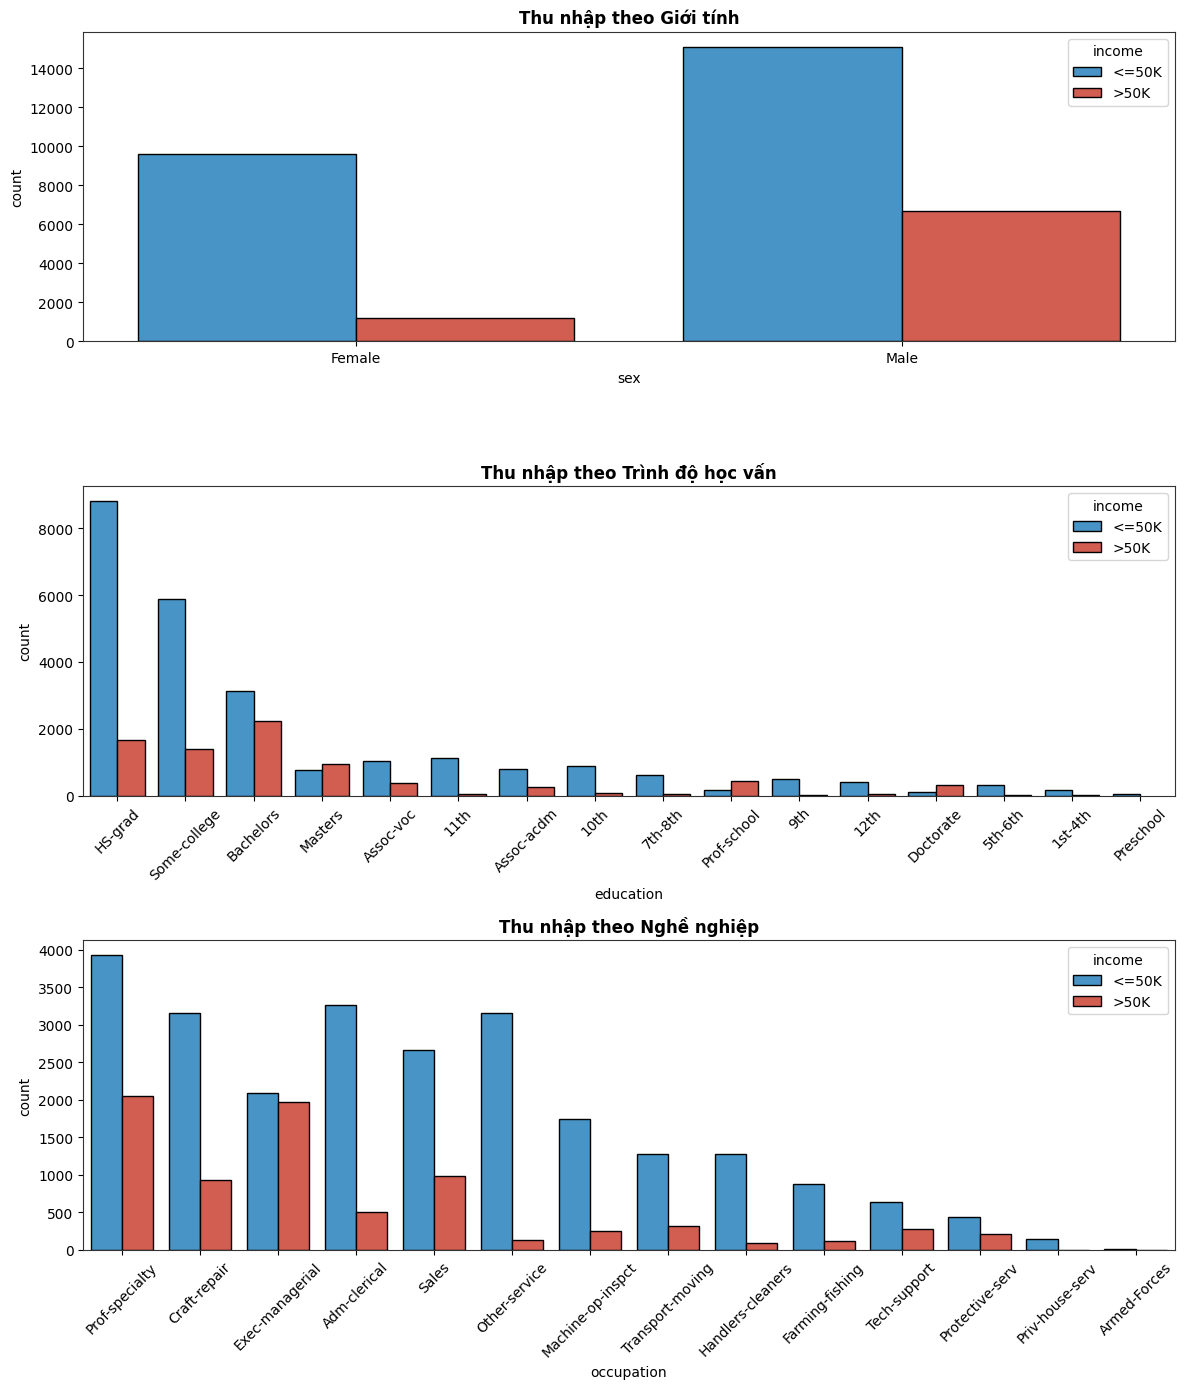

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
sns.countplot(data=df, x='sex', hue='income', palette=['#3498db', '#e74c3c'], ax=axes[0], edgecolor='black')
axes[0].set_title('Thu nhập theo Giới tính', fontweight='bold')

edu_order = df['education'].value_counts().index
sns.countplot(data=df, x='education', hue='income', order=edu_order, palette=['#3498db', '#e74c3c'], ax=axes[1], edgecolor='black')
axes[1].set_title('Thu nhập theo Trình độ học vấn', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

occ_order = df['occupation'].value_counts().index
sns.countplot(data=df, x='occupation', hue='income', order=occ_order, palette=['#3498db', '#e74c3c'], ax=axes[2], edgecolor='black')
axes[2].set_title('Thu nhập theo Nghề nghiệp', fontweight='bold')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 5. Trực quan hóa phân phối đơn biến & Phát hiện Outliers (Task 4 - Dũng)
- Tính toán chỉ số thống kê mô tả: Mean, Min, Max, Median, Std, Skewness, Outliers IQR.
- Vẽ biểu đồ Histogram, Density Plot (KDE) và Boxplot.

In [7]:
num_cols = ['age', 'education_num', 'hours_per_week', 'capital_gain', 'capital_loss']
stats_list = []
for col in num_cols:
    s = df[col]
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    outliers = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    stats_list.append({
        'Biến': col,
        'Mean': round(s.mean(), 2),
        'Std': round(s.std(), 2),
        'Min': s.min(),
        'Q1': q1,
        'Median': s.median(),
        'Q3': q3,
        'Max': s.max(),
        'Skewness': round(s.skew(), 2),
        'Outliers_IQR': outliers,
        'Outliers_Pct': round(outliers / len(s) * 100, 2)
    })
pd.DataFrame(stats_list)

,Biến,Mean,Std,Min,Q1,Median,Q3,Max,Skewness,Outliers_IQR,Outliers_Pct
0,age,38.59,13.64,17,28.0,37.0,48.0,90,0.56,142,0.44
1,education_num,10.08,2.57,1,9.0,10.0,12.0,16,-0.31,1193,3.67
2,hours_per_week,40.44,12.35,1,40.0,40.0,45.0,99,0.23,9002,27.67
3,capital_gain,1078.44,7387.96,0,0.0,0.0,0.0,99999,11.95,2712,8.34
4,capital_loss,87.37,403.10,0,0.0,0.0,0.0,4356,4.59,1519,4.67


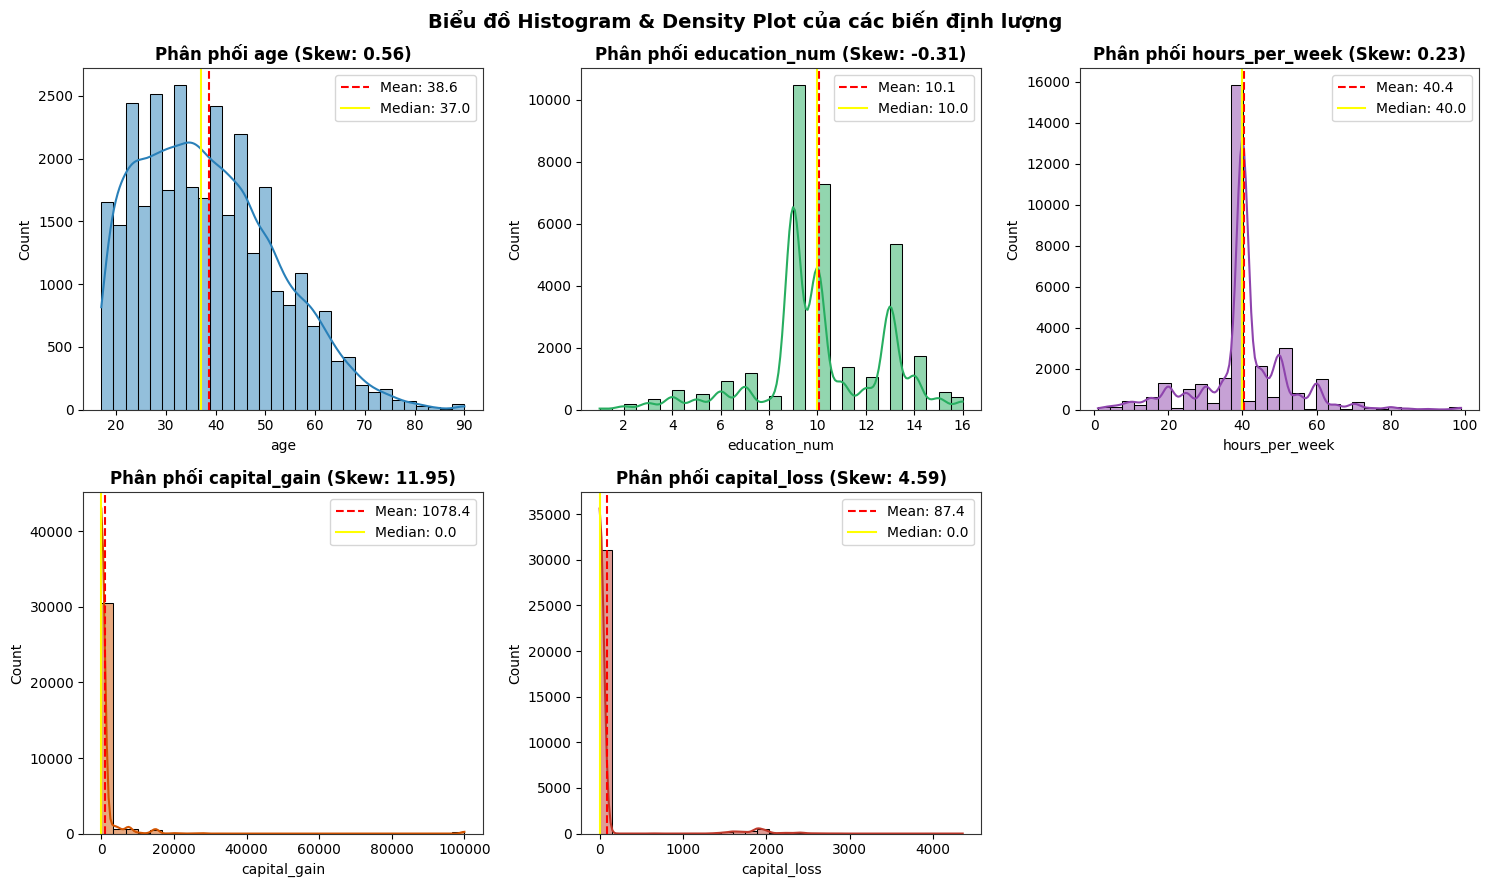

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
colors = ['#2980b9', '#27ae60', '#8e44ad', '#d35400', '#c0392b']
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color=colors[i], bins=30, edgecolor='black')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--', label=f'Mean: {df[col].mean():.1f}')
    axes[i].axvline(df[col].median(), color='yellow', linestyle='-', label=f'Median: {df[col].median():.1f}')
    axes[i].set_title(f'Phân phối {col} (Skew: {df[col].skew():.2f})', fontweight='bold')
    axes[i].legend()
fig.delaxes(axes[5])
plt.suptitle('Biểu đồ Histogram & Density Plot của các biến định lượng', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

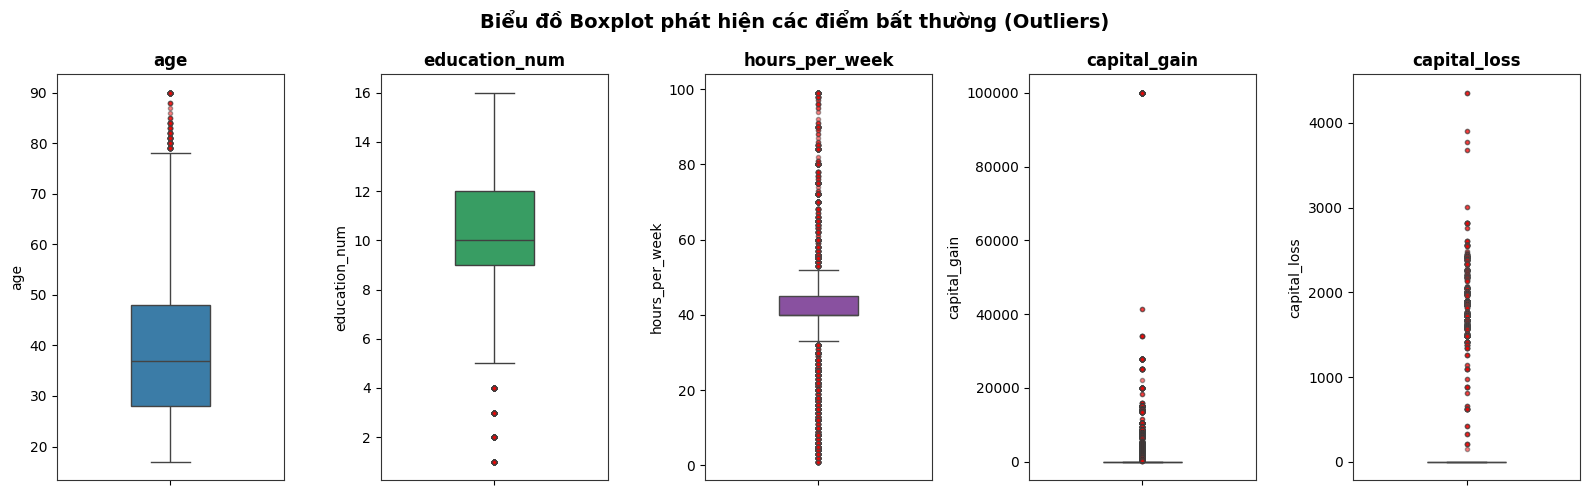

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 5))
for i, col in enumerate(num_cols):
    sns.boxplot(y=df[col], ax=axes[i], color=colors[i], width=0.35,
                flierprops=dict(marker='o', markersize=3, markerfacecolor='red', alpha=0.5))
    axes[i].set_title(col, fontweight='bold')
plt.suptitle('Biểu đồ Boxplot phát hiện các điểm bất thường (Outliers)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Trực quan so sánh nhóm <=50K và >50K (Task 5 - Phúc)
- So sánh phân phối theo độ tuổi, trình độ học vấn và số giờ làm việc qua Boxplot & Violin Plot.

C:\Users\hai phong pc\AppData\Local\Temp\ipykernel_22652\4276001775.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], width=0.4)
C:\Users\hai phong pc\AppData\Local\Temp\ipykernel_22652\4276001775.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], width=0.4)
C:\Users\hai phong pc\AppData\Local\Temp\ipykernel_22652\4276001775.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='income', 

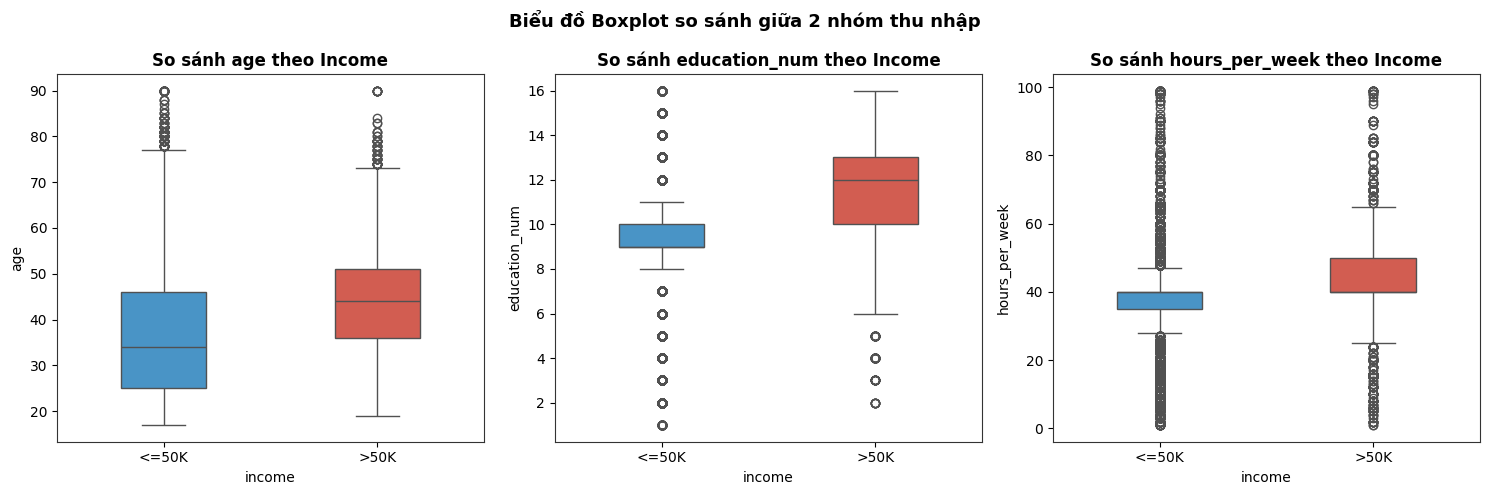

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(['age', 'education_num', 'hours_per_week']):
    sns.boxplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], width=0.4)
    axes[i].set_title(f'So sánh {col} theo Income', fontweight='bold')
plt.suptitle('Biểu đồ Boxplot so sánh giữa 2 nhóm thu nhập', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

C:\Users\hai phong pc\AppData\Local\Temp\ipykernel_22652\2947116035.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], inner='quartile', cut=0)


C:\Users\hai phong pc\AppData\Local\Temp\ipykernel_22652\2947116035.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], inner='quartile', cut=0)
C:\Users\hai phong pc\AppData\Local\Temp\ipykernel_22652\2947116035.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], inner='quartile', cut=0)


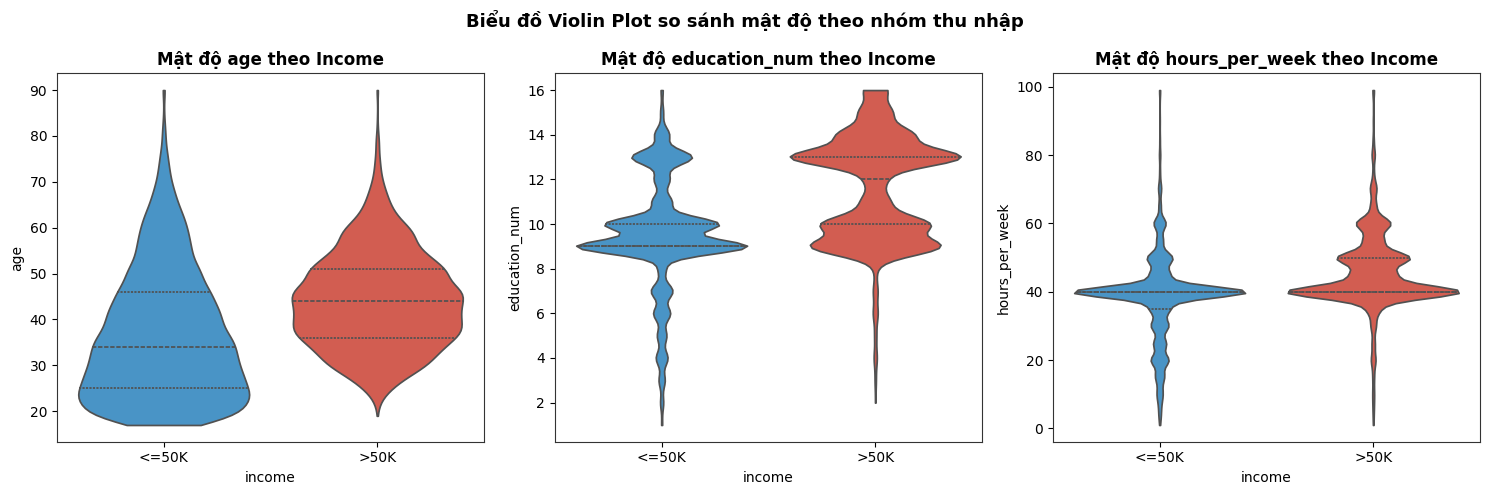

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, col in enumerate(['age', 'education_num', 'hours_per_week']):
    sns.violinplot(data=df, x='income', y=col, ax=axes[i], palette=['#3498db', '#e74c3c'], inner='quartile', cut=0)
    axes[i].set_title(f'Mật độ {col} theo Income', fontweight='bold')
plt.suptitle('Biểu đồ Violin Plot so sánh mật độ theo nhóm thu nhập', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 7. Trực quan nhóm tỷ lệ lồng nhau (Task 6 - Dũng & Ngọc)
- Khảo sát tương tác giữa: Học vấn x Giới tính, Nghề nghiệp x Giới tính, Học vấn x Hôn nhân.

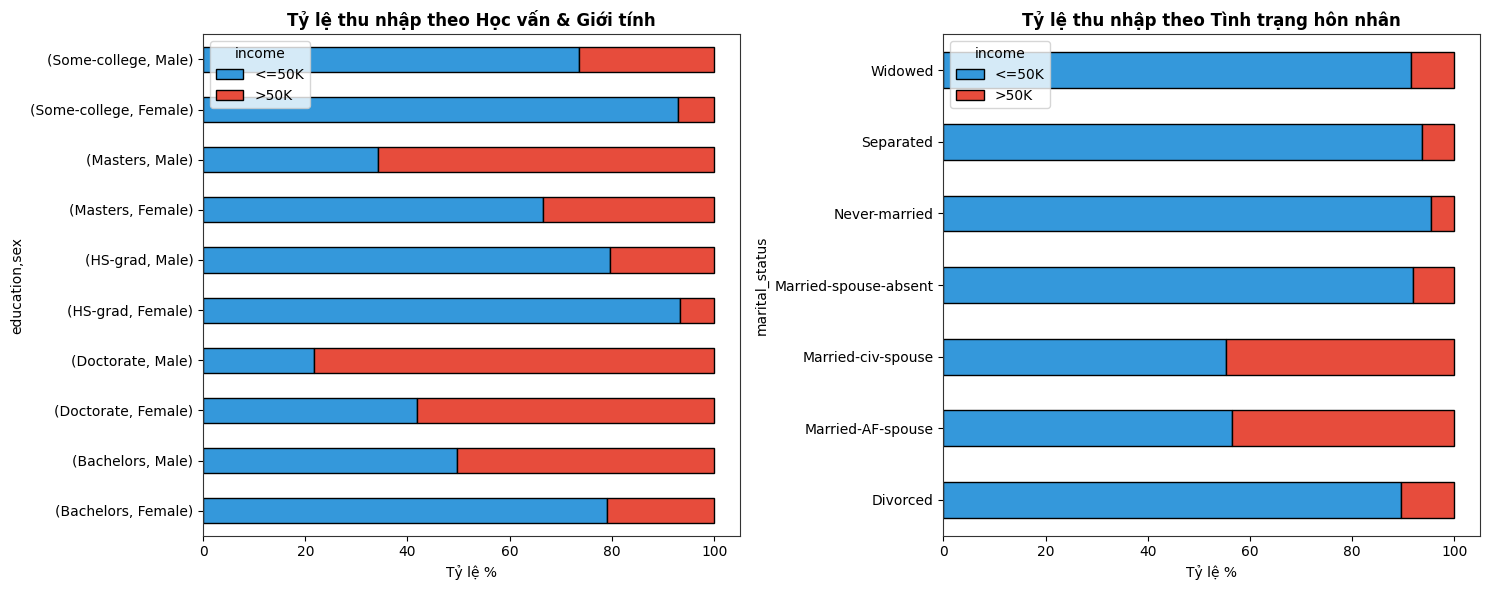

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Học vấn & Giới tính
ct1 = pd.crosstab(index=[df['education'], df['sex']], columns=df['income'], normalize='index') * 100
top_edu = ['HS-grad', 'Some-college', 'Bachelors', 'Masters', 'Doctorate']
ct1_sub = ct1.loc[ct1.index.get_level_values(0).isin(top_edu)]
ct1_sub.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=axes[0], edgecolor='black')
axes[0].set_title('Tỷ lệ thu nhập theo Học vấn & Giới tính', fontweight='bold')
axes[0].set_xlabel('Tỷ lệ %')

# Tình trạng hôn nhân & Học vấn
ct2 = pd.crosstab(index=[df['marital_status']], columns=df['income'], normalize='index') * 100
ct2.plot(kind='barh', stacked=True, color=['#3498db', '#e74c3c'], ax=axes[1], edgecolor='black')
axes[1].set_title('Tỷ lệ thu nhập theo Tình trạng hôn nhân', fontweight='bold')
axes[1].set_xlabel('Tỷ lệ %')

plt.tight_layout()
plt.show()

### 8. Mối liên hệ đa biến & Kiểm định Chi-square (Task 7 - Phúc & Dũng)
- Ma trận tương quan Pearson giữa các biến số.
- Kiểm định Chi-square độc lập với alpha = 0.05.

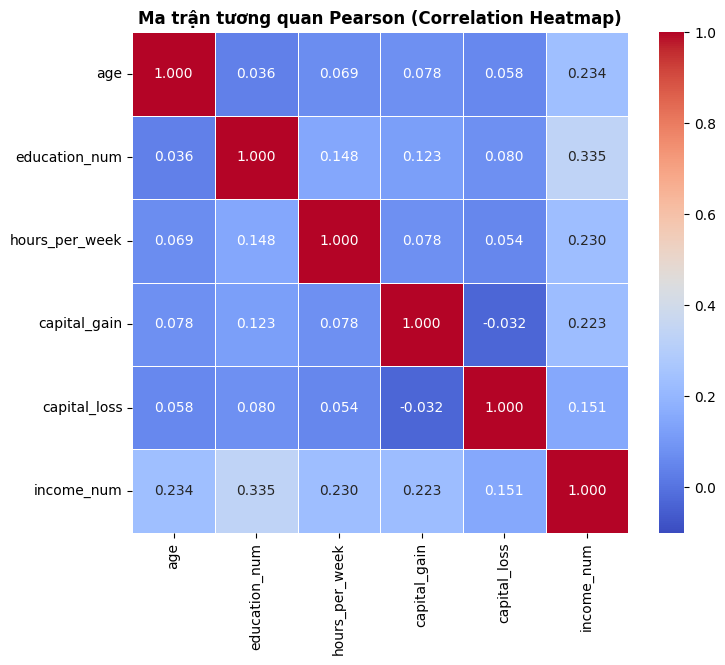

In [13]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(df[num_cols + ['income_num']].corr(), annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.1, vmax=1.0, linewidths=0.5)
plt.title('Ma trận tương quan Pearson (Correlation Heatmap)', fontsize=12, fontweight='bold')
plt.show()

In [14]:
print('KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE (alpha = 0.05):')
for col in ['education', 'sex', 'marital_status', 'occupation']:
    table = pd.crosstab(df[col], df['income'])
    chi2, p_val, dof, _ = chi2_contingency(table)
    status = 'Bác bỏ H0 (Có liên hệ chặt chẽ)' if p_val < 0.05 else 'Chấp nhận H0'
    print(f'[*] {col:<15} x Income: Chi2 = {chi2:<10.2f} | dof = {dof:<3} | p-value = {p_val:.4e} -> {status}')

KẾT QUẢ KIỂM ĐỊNH CHI-SQUARE (alpha = 0.05):
[*] education       x Income: Chi2 = 4428.40    | dof = 15  | p-value = 0.0000e+00 -> Bác bỏ H0 (Có liên hệ chặt chẽ)
[*] sex             x Income: Chi2 = 1516.54    | dof = 1   | p-value = 0.0000e+00 -> Bác bỏ H0 (Có liên hệ chặt chẽ)
[*] marital_status  x Income: Chi2 = 6510.33    | dof = 6   | p-value = 0.0000e+00 -> Bác bỏ H0 (Có liên hệ chặt chẽ)
[*] occupation      x Income: Chi2 = 3197.61    | dof = 13  | p-value = 0.0000e+00 -> Bác bỏ H0 (Có liên hệ chặt chẽ)
